# Tensoranalysis auf Mannigfaltigkeiten

Das Notebook baut die Werkzeuge der Riemannschen Geometrie in Komponenten auf (Metrik, Christoffel-Symbole, kovariante Ableitung, Paralleltransport, Geodäten, Riemann-, Ricci- und Einstein-Tensor, Bianchi-Identitäten, geodätische Abweichung) und berechnet jedes davon mit sympy für die 2-Sphäre, einen Torus, die Schwarzschild-Raumzeit und ein expandierendes Universum. Numerische Experimente integrieren Geodäten und Paralleltransport und finden die Holonomie einer Schleife, den Satz von Gauß–Bonnet, die Lichtablenkung an der Sonne und die Periheldrehung des Merkur.

Wie misst man die Krümmung eines Raums von innen, wenn man nur seine Metrik kennt, und was macht die Krümmung mit geraden Linien und mit Vektoren, die man an ihnen entlangträgt?

#### **Hintergrund**

Tensoranalysis ist die Sprache, in der man einen gekrümmten Raum von innen beschreibt. Gauß zeigte 1827 (Theorema egregium), dass sich die Krümmung einer Fläche allein mit Abständen auf der Fläche messen lässt, ohne den umgebenden Raum anzusehen. Riemann übertrug das 1854 in seinem Habilitationsvortrag auf Räume beliebiger Dimension, Christoffel (1869) sowie Ricci und Levi-Civita (1900) machten daraus einen Kalkül in Komponenten, und Einstein beschrieb damit 1915 die Gravitation als Krümmung der Raumzeit. Zwei klassische Tests folgten direkt: Das Perihel des Merkur wandert pro Jahrhundert um 43″ weiter, als die Newtonsche Gravitation vorhersagt (eine Anomalie, die seit Le Verrier 1859 bekannt war und die Einstein 1915 erklärte), und Sternlicht, das knapp an der Sonne vorbeiläuft, wird um 1,75″ abgelenkt (gemessen bei der Sonnenfinsternis 1919).

Dieselben Werkzeuge tauchen überall auf, wo ein Raum eine eigene Geometrie hat: in der Allgemeinen Relativitätstheorie und der Gravitationswellen-Astronomie, in der Kontinuumsmechanik, in den Konfigurationsräumen von Robotern, in der Informationsgeometrie, wo die Fisher-Information eine Metrik auf einem Raum von Wahrscheinlichkeitsverteilungen ist und der natürliche Gradientenabstieg ihr folgt, und im Geometric Deep Learning auf Netzen und gekrümmten Daten. In der Quantenmechanik ist die Berry-Phase eine Holonomie, und der Raum der reinen Zustände trägt die Fubini–Study-Metrik.

Landkarte:

- **Flächen**
  - Die 2-Sphäre (Exp. 1): Christoffel-Symbole und Krümmung allein aus der Metrik; $K = 1/a^2$.
  - Geodäten auf der Sphäre (Exp. 2): Die geradesten Kurven sind Großkreise, und der Killing-Vektor $\partial_\phi$ liefert eine Erhaltungsgröße.
  - Paralleltransport (Exp. 3): Ein Vektor, den man um eine Schleife trägt, kommt um die eingeschlossene Krümmung gedreht zurück (Holonomie).
  - Der Torus (Exp. 4): außen positiv, innen negativ gekrümmt, insgesamt null (Gauß–Bonnet).
- **Raumzeit**
  - Schwarzschild (Exp. 5): leer (Ricci-flach) und trotzdem gekrümmt; Bianchi-Identität und Gezeitenkräfte.
  - Expandierendes Universum (Exp. 6): Die kontrahierte Bianchi-Identität $\nabla_\mu G^{\mu\nu} = 0$ gilt für jede Expansionsgeschichte und bedeutet Energieerhaltung.
  - Geodäten um die Sonne (Exp. 7): Lichtablenkung und Periheldrehung des Merkur.

Verwandte Notebooks: Geodäten als Variationsproblem und das Noether-Theorem in [Variationsrechnung](https://github.com/deltorobarba/science/blob/main/maths/calculus_of_variations.ipynb), der Satz von Stokes und die Berry-Krümmung in [Vektoranalysis](https://github.com/deltorobarba/science/blob/main/maths/vectorcalculus.ipynb), die Fubini–Study-Metrik und die geometrische Phase auf der Bloch-Kugel in [Projektive Geometrie](https://github.com/deltorobarba/science/blob/main/maths/projectivegeometry.ipynb), Kepler-Bahnen und der Laplace–Runge–Lenz-Vektor in [Quadriken und elliptische Kurven](https://github.com/deltorobarba/science/blob/main/maths/quadrics_ellipticcurves.ipynb).

#### **Theorie**

##### *1. Mannigfaltigkeiten, Tensoren und die Metrik*

Eine $n$-dimensionale **Mannigfaltigkeit** sieht lokal aus wie $\mathbb{R}^n$: Um jeden Punkt gibt es Koordinaten $x^\mu$, $\mu = 1, \dots, n$. Die Physik darf nicht davon abhängen, welche Koordinaten man wählt; deshalb baut man Größen aus Objekten mit einer festen Transformationsregel.

Ein **Tangentialvektor** $V = V^\mu \partial_\mu$ hat Komponenten, die sich wie die Differentiale $dx^\mu$ transformieren; ein **Kovektor** $\omega = \omega_\mu dx^\mu$ transformiert sich wie ein Gradient. Ein **Tensor** vom Typ $(p, q)$ trägt $p$ obere und $q$ untere Indizes und transformiert sich mit einem Faktor pro Index:
$$T'^{\mu\dots}{}_{\nu\dots} = \frac{\partial x'^\mu}{\partial x^\alpha}\cdots\,\frac{\partial x^\beta}{\partial x'^\nu}\cdots\; T^{\alpha\dots}{}_{\beta\dots} .$$
Über einen oben und unten wiederholten Index wird summiert (**Einsteinsche Summenkonvention**). Eine Gleichung zwischen Tensoren, die in einem Koordinatensystem gilt, gilt in allen.

Die **Metrik** $g_{\mu\nu}$ ist ein symmetrischer $(0,2)$-Tensor, der Längen misst, $ds^2 = g_{\mu\nu}\,dx^\mu dx^\nu$. Ihre Inverse $g^{\mu\nu}$ zieht Indizes hoch, $g_{\mu\nu}$ zieht sie herunter: $V_\mu = g_{\mu\nu}V^\nu$.

##### *2. Kovariante Ableitung und Christoffel-Symbole*

Die partielle Ableitung eines Vektors ist kein Tensor: Bei einem Koordinatenwechsel bekommt sie einen Zusatzterm mit den zweiten Ableitungen des Koordinatenwechsels, weil sich die Basisvektoren selbst von Punkt zu Punkt ändern. Die **kovariante Ableitung** fügt eine Korrektur hinzu, die genau diesen Term aufhebt:
$$\nabla_\mu V^\nu = \partial_\mu V^\nu + \Gamma^\nu{}_{\mu\lambda} V^\lambda, \qquad \nabla_\mu \omega_\nu = \partial_\mu \omega_\nu - \Gamma^\lambda{}_{\mu\nu}\,\omega_\lambda .$$
Die **Christoffel-Symbole** $\Gamma$ sind selbst kein Tensor; man kann sie an jedem einzelnen Punkt durch Wahl der Koordinaten zu null machen (**lokale Inertialkoordinaten**).

Der **Levi-Civita-Zusammenhang**, den die Allgemeine Relativitätstheorie benutzt, ist durch zwei Forderungen festgelegt: Er ist **torsionsfrei**, $\Gamma^\lambda{}_{\mu\nu} = \Gamma^\lambda{}_{\nu\mu}$, und **mit der Metrik verträglich**, $\nabla_\rho g_{\mu\nu} = 0$, sodass Längen und Winkel den Paralleltransport überstehen. Zusammen ergeben sie
$$\Gamma^\lambda{}_{\mu\nu} = \tfrac12\, g^{\lambda\sigma}\left(\partial_\mu g_{\sigma\nu} + \partial_\nu g_{\sigma\mu} - \partial_\sigma g_{\mu\nu}\right) .$$

##### *3. Paralleltransport, Geodäten und Erhaltungsgrößen*

Ein Vektor wird entlang einer Kurve $x^\mu(\lambda)$ **parallel transportiert**, wenn seine kovariante Ableitung entlang der Kurve verschwindet:
$$\frac{dV^\mu}{d\lambda} + \Gamma^\mu{}_{\nu\rho}\,\frac{dx^\nu}{d\lambda}\,V^\rho = 0 .$$
Eine **Geodäte** transportiert ihren eigenen Tangentialvektor; sie ist die geradeste mögliche Kurve:
$$\frac{d^2x^\mu}{d\lambda^2} + \Gamma^\mu{}_{\nu\rho}\,\frac{dx^\nu}{d\lambda}\frac{dx^\rho}{d\lambda} = 0 .$$
Geodäten sind auch die stationären Kurven der Länge. Das **Energiefunktional** $E = \int \tfrac12\, g_{\mu\nu}\dot x^\mu \dot x^\nu\, d\lambda$ hat dieselben stationären Kurven, mit $\lambda$ proportional zur Bogenlänge (ein **affiner Parameter**), und seine Euler–Lagrange-Gleichungen sind genau die Geodätengleichung. Sie aufzuschreiben ist oft der schnellste Weg, Christoffel-Symbole von Hand abzulesen.

**Killing-Vektoren:** Hängt die Metrik nicht von einer Koordinate $x^k$ ab, dann ist $p_k = g_{k\nu}\dot x^\nu$ entlang jeder Geodäte erhalten, und $\partial_k$ heißt Killing-Vektor. Auf der Sphäre ($\partial_\phi$) ist das der Drehimpuls $\sin^2\theta\,\dot\phi$, bei Schwarzschild ($\partial_t$, $\partial_\phi$) Energie und Drehimpuls einer Bahn.

##### *4. Krümmung: Riemann, Ricci und Einstein*

Kovariante Ableitungen vertauschen nicht. Im Kommutator heben sich alle Ableitungen von $V$ weg, und übrig bleibt etwas Proportionales zu $V$ selbst; der Faktor ist der **Riemann-Tensor**:
$$[\nabla_\mu, \nabla_\nu]\, V^\rho = R^\rho{}_{\sigma\mu\nu}\, V^\sigma, \qquad R^\rho{}_{\sigma\mu\nu} = \partial_\mu\Gamma^\rho{}_{\nu\sigma} - \partial_\nu\Gamma^\rho{}_{\mu\sigma} + \Gamma^\rho{}_{\mu\lambda}\Gamma^\lambda{}_{\nu\sigma} - \Gamma^\rho{}_{\nu\lambda}\Gamma^\lambda{}_{\mu\sigma} .$$
Seine Kontraktionen sind der **Ricci-Tensor** $R_{\mu\nu} = R^\lambda{}_{\mu\lambda\nu}$, der **Ricci-Skalar** $R = g^{\mu\nu}R_{\mu\nu}$ und der **Einstein-Tensor** $G_{\mu\nu} = R_{\mu\nu} - \tfrac12 R\, g_{\mu\nu}$. Ein Raum mit $R_{\mu\nu} = 0$ heißt **Ricci-flach**; er kann trotzdem gekrümmt sein.

**Zahl der Komponenten:** Mit heruntergezogenem ersten Index ist $R_{\rho\sigma\mu\nu}$ antisymmetrisch in $(\rho\sigma)$ und in $(\mu\nu)$, symmetrisch beim Vertauschen der beiden Paare und erfüllt die erste Bianchi-Identität (Abschnitt 6). Übrig bleiben $n^2(n^2-1)/12$ unabhängige Komponenten: 1 in zwei Dimensionen, 6 in drei und 20 in vier. Auf einer Fläche ist die ganze Krümmung deshalb eine Zahl pro Punkt, die **Gauß-Krümmung** $K = R/2$.

**Vorzeichenkonventionen** wie bei Carroll (2004): Signatur der Metrik $(-,+,+,+)$, Riemann wie oben, Ricci durch Kontraktion des ersten mit dem dritten Index. Damit hat eine Sphäre positive Krümmung.

##### *5. Holonomie und Gauß–Bonnet*

Ein Vektor, den man um eine kleine geschlossene Schleife transportiert, kommt verändert zurück, um $\delta V^\rho = -R^\rho{}_{\sigma\mu\nu}V^\sigma\, \tfrac12\oint x^\mu dx^\nu$. Auf einer Fläche ist das eine Drehung um den Winkel $\int K\, dA$ über das eingeschlossene Gebiet, die **Holonomie** der Schleife. Für einen Breitenkreis $\theta_0$ auf einer Sphäre vom Radius $a$ hat die eingeschlossene Kappe die Fläche $2\pi a^2(1 - \cos\theta_0)$ und $K = 1/a^2$; der Vektor kommt also um $2\pi(1 - \cos\theta_0)$ gedreht zurück.

Über eine ganze geschlossene Fläche summiert ist das der **Satz von Gauß–Bonnet**: $\int K\, dA = 2\pi\chi$ mit der **Euler-Charakteristik** $\chi = 2$ für die Sphäre und $\chi = 0$ für den Torus. Die Gesamtkrümmung hängt nur von der Topologie ab, nicht von der Form.

##### *6. Bianchi-Identitäten*

Der Riemann-Tensor erfüllt eine algebraische Identität, die **erste Bianchi-Identität**
$$R^\rho{}_{\sigma\mu\nu} + R^\rho{}_{\mu\nu\sigma} + R^\rho{}_{\nu\sigma\mu} = 0 ,$$
und eine differentielle, die **zweite Bianchi-Identität**
$$\nabla_\lambda R_{\rho\sigma\mu\nu} + \nabla_\mu R_{\rho\sigma\nu\lambda} + \nabla_\nu R_{\rho\sigma\lambda\mu} = 0 .$$
Die zweite lässt sich in lokalen Inertialkoordinaten prüfen, wo sie sich darauf reduziert, dass partielle Ableitungen vertauschen; als Tensorgleichung gilt sie dann in allen Koordinaten. Zweimal kontrahiert ergibt sie die **kontrahierte Bianchi-Identität**
$$\nabla^\mu G_{\mu\nu} = 0 .$$
Der Einstein-Tensor ist automatisch erhalten. Deshalb kann er links in den **Einsteinschen Feldgleichungen** $G_{\mu\nu} = 8\pi G\, T_{\mu\nu}/c^4$ stehen, deren rechte Seite, der **Energie-Impuls-Tensor** $T_{\mu\nu}$, Energie und Impuls erhält: Die Geometrie erzwingt $\nabla^\mu T_{\mu\nu} = 0$.

##### *7. Geodätische Abweichung und Gezeitenkräfte*

Krümmung lässt benachbarte Geodäten zusammen- oder auseinanderlaufen. Für eine Schar von Geodäten mit Tangente $u^\mu$ und einem Abstandsvektor $\xi^\mu$ zwischen Nachbarn lautet die **Gleichung der geodätischen Abweichung**
$$\frac{D^2\xi^\mu}{d\tau^2} = -R^\mu{}_{\nu\rho\sigma}\,u^\nu\,\xi^\rho\,u^\sigma .$$
Ein ausgedehnter Körper spürt diese Relativbeschleunigung als **Gezeitenkraft**. Für einen Beobachter, der außerhalb einer Masse $M$ ruht (Orthonormalsystem, $G = c = 1$), liefert die Schwarzschild-Metrik
$$ds^2 = -\Big(1 - \frac{2M}{r}\Big)dt^2 + \Big(1 - \frac{2M}{r}\Big)^{-1}dr^2 + r^2 d\Omega^2$$
die Komponenten $R^{\hat r}{}_{\hat t\hat r\hat t} = -2M/r^3$ und $R^{\hat\theta}{}_{\hat t\hat\theta\hat t} = M/r^3$: Benachbarte freie Teilchen werden radial um $2M\xi/r^3$ auseinandergezogen und seitlich um $M\xi/r^3$ zusammengedrückt, das Newtonsche Gezeitenfeld. Der **Kretschmann-Skalar** $R_{\mu\nu\rho\sigma}R^{\mu\nu\rho\sigma}$ ist eine Krümmungsinvariante, die nicht von den Koordinaten abhängt; an ihm unterscheidet man echte Singularitäten von Artefakten der Koordinaten.

##### *8. Bahnen in der Schwarzschild-Raumzeit*

In der Äquatorebene, mit $G = c = 1$, liefern die Killing-Vektoren $\partial_t$ und $\partial_\phi$ die erhaltene Energie $E = (1 - 2M/r)\,\dot t$ und den Drehimpuls $L = r^2\dot\phi$. Die Normierung $g_{\mu\nu}\dot x^\mu\dot x^\nu = -\kappa$ ($\kappa = 1$ für ein massives Teilchen auf einer **zeitartigen Geodäte**, $\kappa = 0$ für Licht auf einer **Nullgeodäte**) wird zu einer Gleichung für $u = 1/r$ als Funktion von $\phi$, der **Bahngleichung**
$$\frac{d^2u}{d\phi^2} + u = \kappa\,\frac{M}{L^2} + 3Mu^2 .$$
Ohne den letzten Term ist das Newtons Gleichung, deren Lösungen Kegelschnitte sind. Der Term $3Mu^2$ ist die Korrektur der Allgemeinen Relativitätstheorie:
- Licht, das mit **Stoßparameter** $b$ an der Sonne vorbeiläuft, wird um $\delta\phi\approx4M/b$ abgelenkt, doppelt so viel wie nach Newton;
- bei einem Planeten auf einer Ellipse mit **Halbparameter** $p = a(1-e^2)$ dreht sich das Perihel pro Umlauf um $\Delta\phi\approx6\pi M/p$.

In SI-Einheiten wird $M\to GM/c^2$, für die Sonne 1477 m.

#### **Code**

Ein kleiner Tensor-Werkzeugkasten mit sympy: Christoffel-Symbole, Riemann-, Ricci- und Einstein-Tensor aus einer beliebigen Metrik, dazu eine numerische rechte Seite für Geodäten und Paralleltransport. Die Indizes stehen in der Reihenfolge der Formeln: `Gam[a, b, c]` $= \Gamma^a{}_{bc}$, `Riem[a, b, c, d]` $= R^a{}_{bcd}$.

In [1]:
# Alles hier Benutzte (numpy, sympy, scipy, matplotlib) ist in Colab vorinstalliert; installiert wird nichts.
import itertools
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid

def simp(e):
    """Vereinfacht, auch mit trigonometrischen Identitäten wie sin(2θ)/(2 tan θ) − cos(2θ) = sin²θ."""
    return sp.trigsimp(sp.expand_trig(sp.simplify(e)))

def christoffel(g, x):
    """Γ^a_bc = ½ g^ad (∂_b g_dc + ∂_c g_db − ∂_d g_bc)."""
    n = len(x)
    ginv = sp.simplify(g.inv())
    Gam = sp.MutableDenseNDimArray.zeros(n, n, n)
    for a in range(n):
        for b in range(n):
            for c in range(b, n):
                val = simp(sum(ginv[a, d] * (sp.diff(g[d, c], x[b]) + sp.diff(g[d, b], x[c]) - sp.diff(g[b, c], x[d]))
                                      for d in range(n)) / 2)
                Gam[a, b, c] = Gam[a, c, b] = val
    return sp.ImmutableDenseNDimArray(Gam)

def riemann(Gam, x):
    """R^a_bcd = ∂_c Γ^a_db − ∂_d Γ^a_cb + Γ^a_ce Γ^e_db − Γ^a_de Γ^e_cb (antisymmetrisch in c, d)."""
    n = len(x)
    Riem = sp.MutableDenseNDimArray.zeros(n, n, n, n)
    for a, b, c, d in itertools.product(range(n), repeat=4):
        if c < d:
            val = simp(sp.diff(Gam[a, d, b], x[c]) - sp.diff(Gam[a, c, b], x[d])
                              + sum(Gam[a, c, e] * Gam[e, d, b] - Gam[a, d, e] * Gam[e, c, b] for e in range(n)))
            Riem[a, b, c, d], Riem[a, b, d, c] = val, -val
    return sp.ImmutableDenseNDimArray(Riem)

def ricci(Riem):
    """R_bd = R^a_bad."""
    n = Riem.shape[0]
    return sp.Matrix(n, n, lambda b, d: simp(sum(Riem[a, b, a, d] for a in range(n))))

def ricci_scalar(Ric, g):
    return simp(sum(g.inv()[b, d] * Ric[b, d] for b in range(g.shape[0]) for d in range(g.shape[0])))

def einstein(Ric, Rs, g):
    return (Ric - Rs * g / 2).applyfunc(simp)

def show(name, T, labels):
    """Druckt die von null verschiedenen Komponenten, mit Koordinatennamen als Indizes."""
    for idx in itertools.product(range(T.shape[0]), repeat=len(T.shape)):
        if T[idx] != 0:
            print(f"  {name}[{','.join(labels[i] for i in idx)}] = {T[idx]}")

def geodesic_rhs(Gam, x):
    """Numerische rechte Seite der Geodätengleichung für den Zustand (x, dx/dλ)."""
    n = len(x)
    f = sp.lambdify(x, Gam.tolist(), "numpy")
    def rhs(lam, y):
        pos, vel = y[:n], y[n:]
        G = np.array(f(*pos), dtype=float)
        return np.concatenate([vel, -np.einsum("abc,b,c->a", G, vel, vel)])
    return rhs

print("Werkzeuge bereit")

Werkzeuge bereit


#### **Experimente**

##### *1. Die 2-Sphäre: Christoffel-Symbole und Krümmung*

Welche Christoffel-Symbole und welche Krümmung hat eine Sphäre vom Radius $a$ mit der Metrik $ds^2 = a^2(d\theta^2 + \sin^2\theta\, d\phi^2)$? Erst vorhersagen: Hängt die Krümmung vom Punkt ab, und wie ändert sie sich, wenn die Sphäre größer wird?

sympy berechnet aus der Metrik mit der Formel aus Abschnitt 2 der Theorie die Christoffel-Symbole, dann den Riemann-Tensor, seine Kontraktion zum Ricci-Tensor und den Ricci-Skalar. Hinein geht nur die Metrik; ein Bild der Sphäre im dreidimensionalen Raum wird nicht benutzt.

**Hintergrund & Fachbegriffe:**
- **Metrik der Sphäre:** $\theta$ ist der Polabstand (0 am Nordpol), $\phi$ die geographische Länge. Ein Schritt $d\phi$ legt nahe den Polen weniger Weg zurück, daher der Faktor $\sin^2\theta$.
- **Christoffel-Symbole:** beschreiben, wie sich die Koordinaten-Basisvektoren von Punkt zu Punkt drehen; sie sind schon für Polarkoordinaten in der flachen Ebene ungleich null.
- **Riemann-Tensor und Gauß-Krümmung:** Der Riemann-Tensor misst die Krümmung, die kein Koordinatenwechsel beseitigen kann; auf einer Fläche ist sie eine Zahl pro Punkt, $K = R/2$.
- **Innere Krümmung:** Krümmung, die man von innen misst, nur mit Abständen auf der Fläche (Theorema egregium von Gauß). Ein Zylinder ist innerlich flach, eine Sphäre nicht.

In [2]:
a = sp.symbols("a", positive=True)
th, ph = sp.symbols("theta phi")
X_s2 = [th, ph]
g_s2 = sp.diag(a ** 2, a ** 2 * sp.sin(th) ** 2)

Gam_s2 = christoffel(g_s2, X_s2)
Riem_s2 = riemann(Gam_s2, X_s2)
Ric_s2 = ricci(Riem_s2)
R_s2 = ricci_scalar(Ric_s2, g_s2)

print("Christoffel-Symbole Γ^a_bc:")
show("Γ", Gam_s2, ["θ", "φ"])
print("Riemann-Tensor R^a_bcd:")
show("R", Riem_s2, ["θ", "φ"])
print(f"Ricci-Tensor: {Ric_s2.tolist()}")
print(f"Ricci-Skalar R = {R_s2},  Gauß-Krümmung K = R/2 = {sp.simplify(R_s2 / 2)}")
print(f"Unabhängige Komponenten des Riemann-Tensors in n Dimensionen, n²(n²−1)/12: " + ", ".join(f"n={n}: {n**2 * (n**2 - 1) // 12}" for n in (2, 3, 4)))

Christoffel-Symbole Γ^a_bc:
  Γ[θ,φ,φ] = -sin(2*theta)/2
  Γ[φ,θ,φ] = 1/tan(theta)
  Γ[φ,φ,θ] = 1/tan(theta)
Riemann-Tensor R^a_bcd:
  R[θ,φ,θ,φ] = sin(theta)**2
  R[θ,φ,φ,θ] = -sin(theta)**2
  R[φ,θ,θ,φ] = -1
  R[φ,θ,φ,θ] = 1
Ricci-Tensor: [[1, 0], [0, sin(theta)**2]]
Ricci-Skalar R = 2/a**2,  Gauß-Krümmung K = R/2 = a**(-2)
Unabhängige Komponenten des Riemann-Tensors in n Dimensionen, n²(n²−1)/12: n=2: 1, n=3: 6, n=4: 20


* Die von null verschiedenen **Christoffel-Symbole** sind $\Gamma^\theta{}_{\phi\phi} = -\sin\theta\cos\theta$ (ausgegeben als $-\sin 2\theta/2$) und $\Gamma^\phi{}_{\theta\phi} = \Gamma^\phi{}_{\phi\theta} = \cot\theta$. Sie hängen nicht von $a$ ab, weil der Radius die Metrik nur mit einer Konstanten multipliziert.
* Der **Riemann-Tensor** hat eine einzige unabhängige Komponente, $R^\theta{}_{\phi\theta\phi} = \sin^2\theta$; die vier ausgegebenen Einträge sind diese Komponente, umgeordnet durch die Antisymmetrien und mit dem ersten Index über verschiedene Metrikfaktoren hochgezogen. Der Ricci-Skalar ist $R = 2/a^2$, die Gauß-Krümmung also $K = 1/a^2$: an jedem Punkt gleich und kleiner für eine größere Sphäre, die von innen flacher aussieht.
* Die **letzte Zeile** zählt die unabhängigen Komponenten, $n^2(n^2-1)/12$: 1 auf einer Fläche, 6 in drei Dimensionen und 20 in der vierdimensionalen Raumzeit. Deshalb sagt auf einer Fläche die eine Zahl $K$ alles über die Krümmung.

##### *2. Geodäten auf der Sphäre*

Sind die Geodäten Großkreise, und erhalten sie ihre Geschwindigkeit und den Drehimpuls, der zum Killing-Vektor $\partial_\phi$ gehört? Erst vorhersagen: Eine Geodäte startet auf dem Äquator nach Nordosten. Wie weit nach Norden kommt sie?

Die Geodätengleichung mit den Christoffel-Symbolen aus Experiment 1 ($a = 1$) wird numerisch für eine volle Umdrehung integriert, $\lambda$ von 0 bis $2\pi$. Ist die Kurve ein Großkreis, liegen alle ihre Punkte in einer Ebene durch den Mittelpunkt der Sphäre; der Code nimmt die Ebene durch den Mittelpunkt und zwei frühe Punkte der Kurve und misst den Abstand jedes Punkts von ihr. Außerdem verfolgt er $g(v, v)$ und $\sin^2\theta\,\dot\phi$ entlang der Kurve (Theorie, Abschnitt 3).

**Hintergrund & Fachbegriffe:**
- **Großkreis:** der Schnitt der Sphäre mit einer Ebene durch ihren Mittelpunkt, wie der Äquator oder ein Meridian; der kürzeste Weg zwischen zwei Punkten der Sphäre, dem Langstreckenflüge folgen.
- **Affiner Parameter:** ein Parameter entlang der Geodäte, proportional zur Bogenlänge; mit ihm ist die Geschwindigkeit $g(v, v)$ konstant.
- **Killing-Vektor $\partial_\phi$:** Die Metrik hängt nicht von $\phi$ ab (Drehungen um die Polachse), deshalb ist $\sin^2\theta\,\dot\phi$ entlang jeder Geodäte erhalten. Auf der Sphäre ist das die Clairaut-Relation.

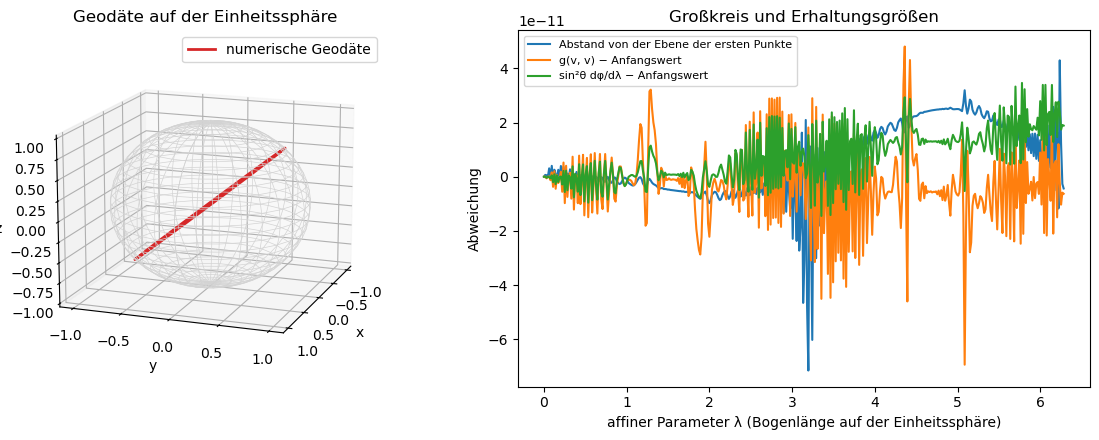

größter Abstand von der Großkreisebene: 7.1e-11
größte Drift von g(v,v): 6.9e-11,  von sin²θ φ': 3.5e-11


In [3]:
rhs_s2 = geodesic_rhs(Gam_s2.subs(a, 1), X_s2)           # unit sphere
y0 = [np.pi / 2, 0.0, -np.cos(np.radians(45)), np.sin(np.radians(45))]   # on the equator, heading north-east
sol = solve_ivp(rhs_s2, [0, 2 * np.pi], y0, rtol=1e-11, atol=1e-12, dense_output=True)
lam = np.linspace(0, 2 * np.pi, 400)
th_n, ph_n, dth, dph = sol.sol(lam)
xyz = np.array([np.sin(th_n) * np.cos(ph_n), np.sin(th_n) * np.sin(ph_n), np.cos(th_n)])

normal = np.cross(xyz[:, 0], xyz[:, 40])
normal /= np.linalg.norm(normal)
speed2 = dth ** 2 + np.sin(th_n) ** 2 * dph ** 2               # g(v, v)
L_phi = np.sin(th_n) ** 2 * dph                                 # conserved because the metric does not depend on φ

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
u_, v_ = np.meshgrid(np.linspace(0, np.pi, 30), np.linspace(0, 2 * np.pi, 30))
ax.plot_wireframe(np.sin(u_) * np.cos(v_), np.sin(u_) * np.sin(v_), np.cos(u_), color="lightgrey", lw=0.5)
ax.plot(*xyz, c="tab:red", lw=2, label="numerische Geodäte")
ax.view_init(elev=15, azim=20)
ax.set_title("Geodäte auf der Einheitssphäre")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.legend()
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(lam, normal @ xyz, label="Abstand von der Ebene der ersten Punkte")
ax2.plot(lam, speed2 - speed2[0], label="g(v, v) − Anfangswert")
ax2.plot(lam, L_phi - L_phi[0], label="sin²θ dφ/dλ − Anfangswert")
ax2.set_xlabel("affiner Parameter λ (Bogenlänge auf der Einheitssphäre)")
ax2.set_ylabel("Abweichung")
ax2.set_title("Großkreis und Erhaltungsgrößen")
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"größter Abstand von der Großkreisebene: {np.max(np.abs(normal @ xyz)):.1e}")
print(f"größte Drift von g(v,v): {np.max(np.abs(speed2 - speed2[0])):.1e},  von sin²θ φ': {np.max(np.abs(L_phi - L_phi[0])):.1e}")

* Das **linke Bild** zeigt die numerische Geodäte (rot) auf der Einheitssphäre. Die Kamera schaut zufällig fast genau entlang der Ebene der Kurve, deshalb erscheint sie als nahezu gerade Linie durch die Sphäre; eine Kurve, die nicht in einer Ebene liegt, könnte aus keiner Richtung so aussehen. Der Großkreis ist um 45° gegen den Äquator geneigt und erreicht 45° Nord und 45° Süd.
* Das **rechte Bild** zeigt drei Abweichungen entlang der Kurve: den Abstand von der Ebene durch den Mittelpunkt (blau), die Änderung der Geschwindigkeit $g(v, v)$ (orange) und die Änderung von $\sin^2\theta\,\dot\phi$ (grün). Alle drei bleiben unter $10^{-10}$, der Genauigkeit des Integrators.
* Die **Ausgabe** nennt die Höchstwerte: Abstand von der Ebene $7{,}1\cdot10^{-11}$, Drift von $g(v, v)$ $6{,}9\cdot10^{-11}$ und der Killing-Größe $3{,}5\cdot10^{-11}$. Die Geodäte ist ein Großkreis, und beide Größen sind erhalten.

##### *3. Paralleltransport um einen Breitenkreis*

Um wie viel dreht sich ein Vektor, den man einmal um den Kreis $\theta = \theta_0$ parallel transportiert, und ist das die Krümmung, integriert über die eingeschlossene Kappe? Erst vorhersagen: Was passiert mit dem Vektor auf einem sehr kleinen Kreis nahe dem Pol, und was auf dem Äquator?

Der Vektor startet als Einheitsvektor nach Süden, $e_\theta$, und wird mit der Gleichung des Paralleltransports einmal um den Kreis getragen; das wird für 40 Kreise vom Nordpol bis nahe an den Südpol wiederholt. Nach einer Runde wird sein Winkel zu $e_\theta$ im Orthonormalsystem $(e_\theta, e_\phi/\sin\theta_0)$ gemessen. Abschnitt 5 der Theorie sagt $2\pi(1 - \cos\theta_0)$ voraus, bis auf ganze Umdrehungen.

**Hintergrund & Fachbegriffe:**
- **Paralleltransport:** einen Vektor entlang einer Kurve verschieben, ohne ihn zu drehen, von der Fläche aus gesehen; auf einer gekrümmten Fläche hängt das Ergebnis vom Weg ab.
- **Holonomie:** die Drehung, die ein Vektor auf einer geschlossenen Schleife aufsammelt; auf einer Fläche gleich der Krümmung, integriert über die eingeschlossene Fläche.
- **Breitenkreis:** Für $\theta_0\neq90°$ ist er keine Geodäte, nur der Äquator ist eine; entlang des Breitenkreises laufen der transportierte Vektor und die Tangente der Kurve langsam auseinander.
- **Orthonormalsystem:** Basisvektoren der Länge eins, die senkrecht aufeinander stehen. Auf der Einheitssphäre hat $e_\phi$ die Länge $\sin\theta_0$ und wird durch sie geteilt.

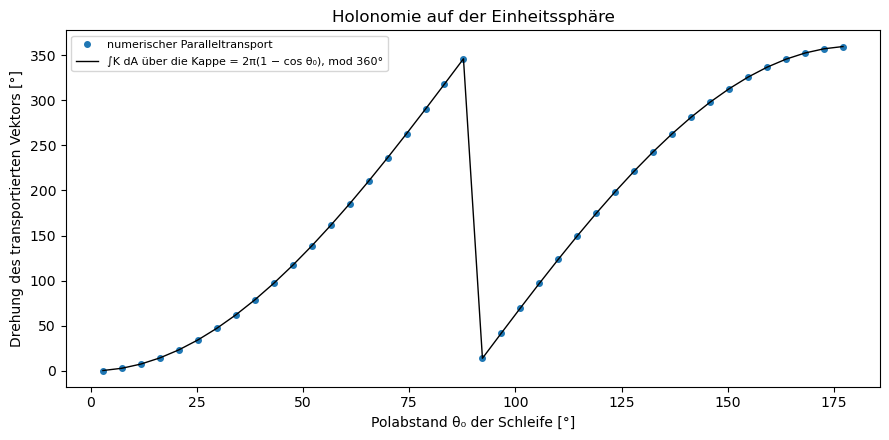

größte Abweichung von 2π(1 − cos θ₀) mod 2π: 1.85e-11 Grad
Beispiel θ₀ = 60°: Drehung 180.0000°, Kappenfläche/a² = 180.0000°


In [4]:
Gam_num = sp.lambdify([th, ph], Gam_s2.subs(a, 1).tolist(), "numpy")

def transport_angle(theta0):
    """Paralleltransport von e_θ einmal um θ = theta0 (Kurve x(λ) = (theta0, λ)); gibt den Drehwinkel zurück."""
    def rhs(lam, V):
        G = np.array(Gam_num(theta0, lam), dtype=float)
        return -np.einsum("abc,b,c->a", G, np.array([0.0, 1.0]), V)     # dx/dλ = (0, 1)
    V_end = solve_ivp(rhs, [0, 2 * np.pi], [1.0, 0.0], rtol=1e-11, atol=1e-12).y[:, -1]
    return np.arctan2(V_end[1] * np.sin(theta0), V_end[0]) % (2 * np.pi)   # angle in the orthonormal frame

thetas0 = np.linspace(0.05, np.pi - 0.05, 40)
measured = np.array([transport_angle(t) for t in thetas0])
predicted = (2 * np.pi * (1 - np.cos(thetas0))) % (2 * np.pi)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.degrees(thetas0), np.degrees(measured), "o", ms=4, label="numerischer Paralleltransport")
ax.plot(np.degrees(thetas0), np.degrees(predicted), c="black", lw=1, label="∫K dA über die Kappe = 2π(1 − cos θ₀), mod 360°")
ax.set_xlabel("Polabstand θ₀ der Schleife [°]")
ax.set_ylabel("Drehung des transportierten Vektors [°]")
ax.set_title("Holonomie auf der Einheitssphäre")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
err = np.minimum(np.abs(measured - predicted), 2 * np.pi - np.abs(measured - predicted))
print(f"größte Abweichung von 2π(1 − cos θ₀) mod 2π: {np.degrees(err.max()):.2e} Grad")
print(f"Beispiel θ₀ = 60°: Drehung {np.degrees(transport_angle(np.pi / 3)):.4f}°, Kappenfläche/a² = {np.degrees(2 * np.pi * (1 - 0.5)):.4f}°")

* Das **Bild** zeigt den Drehwinkel nach einer Runde gegen den Polabstand $\theta_0$ des Kreises: numerischer Paralleltransport (Punkte) und die eingeschlossene Krümmung $2\pi(1 - \cos\theta_0)$ modulo 360° (Linie). Sie stimmen für alle 40 Kreise überein. Nahe dem Nordpol ist die Kappe winzig, und der Vektor dreht sich kaum; der Winkel wächst mit der Fläche der Kappe.
* Am Äquator ($\theta_0 = 90°$) ist die Kappe eine Halbkugel, die Drehung ist volle 360°, und der Vektor kommt unverändert zurück; dort springt die Linie von 360° auf 0°. Der Äquator ist eine Geodäte, und entlang einer Geodäte behält ein transportierter Vektor seinen Winkel zur Tangente. Jenseits des Äquators wächst der Winkel weiter Richtung 720°, was modulo 360° als zweiter Anstieg von 0° auf 360° erscheint.
* Die **Ausgabe** nennt die größte Abweichung, $1{,}85\cdot10^{-11}$ Grad, und das Beispiel $\theta_0 = 60°$: Die Kappe hat die Fläche $\pi$, eine halbe Halbkugel, und der Vektor kommt um genau 180° gedreht zurück, zeigt also nach Norden statt nach Süden.

##### *4. Der Torus: Krümmung mit wechselndem Vorzeichen, und Gauß–Bonnet*

Wo ist ein Torus gekrümmt wie eine Sphäre und wo wie ein Sattel, und verschwindet seine Gesamtkrümmung, wie Gauß–Bonnet verlangt? Erst vorhersagen: Welches Vorzeichen hat die Krümmung auf dem äußeren Äquator, auf dem inneren Äquator und auf dem oberen Kreis?

Der Torus mit Röhrenradius $r$ und Mittellinienradius $R$ hat $ds^2 = r^2 d\theta^2 + (R + r\cos\theta)^2 d\phi^2$, wobei $\theta$ um die Röhre läuft ($\theta = 0$ auf dem äußeren Äquator). sympy berechnet $K$ aus dieser Metrik mit denselben Werkzeugen wie für die Sphäre; für $R = 2$, $r = 1$ wird die Gesamtkrümmung $\int K\,dA$ numerisch integriert und mit der der Sphäre verglichen (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **Torus:** die Oberfläche eines Rings oder Donuts; $R$ ist der Abstand vom Mittelpunkt des Lochs zur Mitte der Röhre, $r$ der Radius der Röhre.
- **Vorzeichen der Gauß-Krümmung:** $K>0$ heißt, die Fläche biegt sich in alle Richtungen gleich (wie eine Sphäre), $K<0$, sie biegt sich in einer Richtung nach oben und in der anderen nach unten (wie ein Sattel), $K = 0$, sie ist in mindestens einer Richtung gerade.
- **Euler-Charakteristik:** eine topologische Zahl, Ecken minus Kanten plus Flächen einer beliebigen Triangulierung der Fläche; $\chi = 2$ für die Sphäre, $\chi = 0$ für den Torus.
- **Flächenelement:** $dA = \sqrt{\det g}\,d\theta\,d\phi$, nötig, um in Koordinaten über die Fläche zu integrieren.

Gauß-Krümmung des Torus: K = cos(theta)/(r*(R + r*cos(theta)))


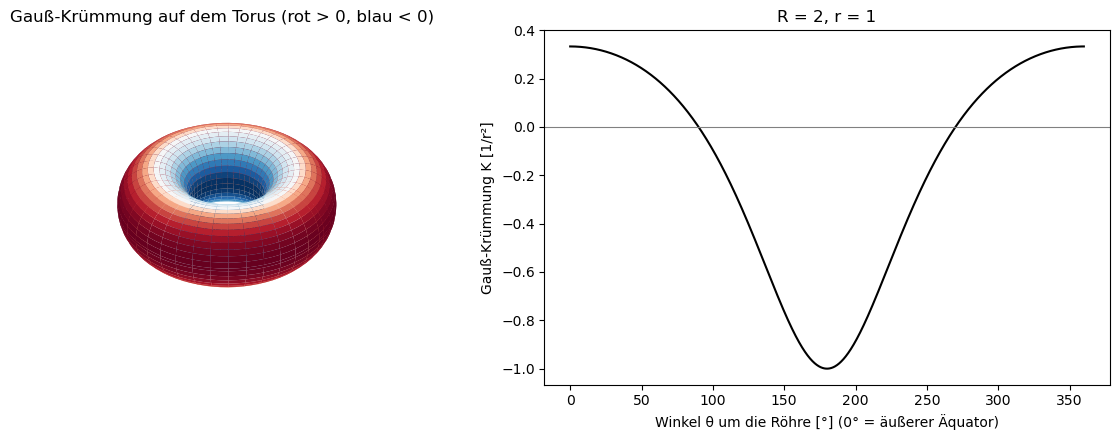

∫K dA, Torus:  -2.09e-15   (Gauß–Bonnet: 2π·χ = 0)
∫K dA, Sphäre: 12.566371   (Gauß–Bonnet: 2π·2 = 12.566371)


In [5]:
Rt, rt = sp.symbols("R r", positive=True)
g_t = sp.diag(rt ** 2, (Rt + rt * sp.cos(th)) ** 2)
Gam_t = christoffel(g_t, X_s2)
K_t = sp.simplify(ricci_scalar(ricci(riemann(Gam_t, X_s2)), g_t) / 2)
print(f"Gauß-Krümmung des Torus: K = {K_t}")

vals = {Rt: 2.0, rt: 1.0}
K_num = sp.lambdify(th, K_t.subs(vals), "numpy")
sqrt_det = sp.lambdify(th, sp.sqrt(g_t.det()).subs(vals), "numpy")
tt = np.linspace(0, 2 * np.pi, 2001)
total_K_torus = trapezoid(K_num(tt) * sqrt_det(tt), tt) * 2 * np.pi        # ∫∫ K √g dθ dφ
total_K_sphere = float(sp.integrate(sp.integrate((R_s2 / 2 * sp.sqrt(g_s2.det())).subs(a, 1), (th, 0, sp.pi)), (ph, 0, 2 * sp.pi)))

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
T_, P_ = np.meshgrid(np.linspace(0, 2 * np.pi, 80), np.linspace(0, 2 * np.pi, 80))
Xt, Yt, Zt = (2 + np.cos(T_)) * np.cos(P_), (2 + np.cos(T_)) * np.sin(P_), np.sin(T_)
Kc = K_num(T_)
norm = plt.matplotlib.colors.TwoSlopeNorm(vmin=Kc.min(), vcenter=0.0, vmax=Kc.max())
ax.plot_surface(Xt, Yt, Zt, facecolors=plt.cm.RdBu_r(norm(Kc)), linewidth=0, antialiased=True, shade=False)
ax.view_init(elev=35, azim=-60)
ax.set_box_aspect((1, 1, 0.35))
ax.set_title("Gauß-Krümmung auf dem Torus (rot > 0, blau < 0)")
ax.set_axis_off()
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(np.degrees(tt), K_num(tt), c="black")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_xlabel("Winkel θ um die Röhre [°] (0° = äußerer Äquator)")
ax2.set_ylabel("Gauß-Krümmung K [1/r²]")
ax2.set_title("R = 2, r = 1")
fig.tight_layout()
plt.show()
print(f"∫K dA, Torus:  {total_K_torus:.2e}   (Gauß–Bonnet: 2π·χ = 0)")
print(f"∫K dA, Sphäre: {total_K_sphere:.6f}   (Gauß–Bonnet: 2π·2 = {4 * np.pi:.6f})")

* Die **erste Ausgabezeile** gibt $K = \cos\theta/(r(R + r\cos\theta))$. Es ist positiv auf der äußeren Hälfte der Röhre ($\cos\theta>0$), negativ auf der inneren und null auf dem oberen und unteren Kreis ($\theta = \pm90°$).
* Das **linke Bild** färbt den Torus nach $K$: rot außen, wo er wie eine Sphäre gekrümmt ist, blau um das Loch, wo er wie ein Sattel gekrümmt ist, weiß auf dem oberen Kreis dazwischen. Das **rechte Bild** zeigt $K$ um die Röhre für $R = 2$, $r = 1$: von $+1/3$ auf dem äußeren bis $-1$ auf dem inneren Äquator. Die negativen Werte sind größer, aber die innere Hälfte hat weniger Fläche, und beides gleicht sich aus.
* Die **Ausgabe** nennt die Gesamtkrümmung: $-2\cdot10^{-15}$ für den Torus, also null bis auf Rundung, und $12{,}566371 = 4\pi$ für die Einheitssphäre. Das ist Gauß–Bonnet mit $\chi = 0$ und $\chi = 2$: Keine Verformung der Fläche kann diese Zahlen ändern, nur ein Wechsel der Topologie.

##### *5. Schwarzschild: Vakuum, erste Bianchi-Identität und Gezeitenkräfte*

Ist die Schwarzschild-Raumzeit leer (Ricci-flach), erfüllt ihr Riemann-Tensor die erste Bianchi-Identität, und wie stark sind ihre Gezeitenkräfte? Erst vorhersagen: Wo ist die Gezeitendehnung zwischen Kopf und Füßen größer, am Horizont eines kleinen oder am Horizont eines supermassereichen Schwarzen Lochs?

Metrik mit $G = c = 1$: $ds^2 = -(1 - 2M/r)\,dt^2 + (1 - 2M/r)^{-1}dr^2 + r^2 d\Omega^2$. sympy berechnet alle Christoffel-Symbole und Riemann-Komponenten, prüft den Ricci-Tensor und die 256 Komponenten der ersten Bianchi-Identität und berechnet den Kretschmann-Skalar und die Gezeitenkomponenten im System eines ruhenden Beobachters. Die radiale Gezeitenbeschleunigung $2GM\ell/r^3$ über einen Körper der Länge $\ell = 2$ m wird dann in SI-Einheiten für die Erde, die Sonne und zwei Schwarze Löcher ausgewertet (Theorie, Abschnitte 6 und 7).

**Hintergrund & Fachbegriffe:**
- **Schwarzschild-Metrik:** die Raumzeit außerhalb einer nicht rotierenden kugelsymmetrischen Masse (Schwarzschild 1916); $r = 2M$, in SI-Einheiten $2GM/c^2$, ist der **Ereignishorizont**.
- **Ricci-flach:** $R_{\mu\nu} = 0$, die Einsteinschen Feldgleichungen im Vakuum. Der Riemann-Tensor kann trotzdem ungleich null sein: Krümmung ohne Materie, wie im leeren Raum um einen Stern.
- **Kretschmann-Skalar:** $R_{\mu\nu\rho\sigma}R^{\mu\nu\rho\sigma}$, in jedem Koordinatensystem gleich. Bleibt er endlich, wo die Metrik singulär aussieht, ist diese Singularität nur ein Artefakt der Koordinaten.
- **Gezeitenbeschleunigung:** der Unterschied der Schwerebeschleunigung zwischen zwei benachbarten Punkten, beschrieben durch die geodätische Abweichung.
- **Sgr A\*:** das Schwarze Loch im Zentrum der Milchstraße, etwa 4,3 Millionen Sonnenmassen.

In [6]:
t, r, M = sp.symbols("t r M", positive=True)
X_s = [t, r, th, ph]
f_s = 1 - 2 * M / r
g_s = sp.diag(-f_s, 1 / f_s, r ** 2, r ** 2 * sp.sin(th) ** 2)
Gam_s = christoffel(g_s, X_s)
Riem_s = riemann(Gam_s, X_s)
Ric_s = ricci(Riem_s)
print(f"Ricci-Tensor von Schwarzschild: {'null (Vakuum)' if Ric_s == sp.zeros(4, 4) else Ric_s}")

# Erste Bianchi-Identität: R^a_bcd + R^a_cdb + R^a_dbc = 0
viol = [sp.simplify(Riem_s[a_, b, c, d] + Riem_s[a_, c, d, b] + Riem_s[a_, d, b, c])
        for a_, b, c, d in itertools.product(range(4), repeat=4)]
print(f"Erste Bianchi-Identität: {sum(v != 0 for v in viol)} verletzte Komponenten von {len(viol)}")

# Kretschmann-Skalar für diese diagonale Metrik: Σ (R^a_bcd)² g_aa g^bb g^cc g^dd
gd, gi = [g_s[i, i] for i in range(4)], [1 / g_s[i, i] for i in range(4)]
kretschmann = sp.simplify(sum(Riem_s[a_, b, c, d] ** 2 * gd[a_] * gi[b] * gi[c] * gi[d]
                              for a_, b, c, d in itertools.product(range(4), repeat=4)))
print(f"Kretschmann-Skalar: {kretschmann}")

# Gezeitentensor im ruhenden Orthonormalsystem: R^r̂_t̂r̂t̂ = R^r_trt / (1 − 2M/r), ebenso für θ
tidal_r = sp.simplify(Riem_s[1, 0, 1, 0] / f_s)
tidal_th = sp.simplify(Riem_s[2, 0, 2, 0] / f_s)
print(f"R^r̂_t̂r̂t̂ = {tidal_r},   R^θ̂_t̂θ̂t̂ = {tidal_th}")

# Größe der radialen Gezeitenbeschleunigung 2GM L / r³ über einen 2 m langen Körper, in SI-Einheiten
G_SI, c_SI = 6.674e-11, 2.998e8
cases = [("Erdoberfläche", 5.972e24, 6.371e6), ("Sonnenoberfläche", 1.989e30, 6.957e8),
         ("Horizont, 10 Sonnenmassen", 10 * 1.989e30, 2 * G_SI * 10 * 1.989e30 / c_SI ** 2),
         ("Horizont, Sgr A* (4,3e6 Sonnenmassen)", 4.3e6 * 1.989e30, 2 * G_SI * 4.3e6 * 1.989e30 / c_SI ** 2)]
print("\nRadiale Gezeitenbeschleunigung zwischen Kopf und Füßen (2 m):")
for name, mass, radius in cases:
    print(f"  {name:38s} r = {radius:9.3e} m:  Δa = {2 * G_SI * mass * 2.0 / radius ** 3:9.2e} m/s²")

Ricci-Tensor von Schwarzschild: null (Vakuum)


Erste Bianchi-Identität: 0 verletzte Komponenten von 256
Kretschmann-Skalar: 48*M**2/r**6
R^r̂_t̂r̂t̂ = -2*M/r**3,   R^θ̂_t̂θ̂t̂ = M/r**3

Radiale Gezeitenbeschleunigung zwischen Kopf und Füßen (2 m):
  Erdoberfläche                          r = 6.371e+06 m:  Δa =  6.17e-06 m/s²
  Sonnenoberfläche                       r = 6.957e+08 m:  Δa =  1.58e-06 m/s²
  Horizont, 10 Sonnenmassen              r = 2.954e+04 m:  Δa =  2.06e+08 m/s²
  Horizont, Sgr A* (4,3e6 Sonnenmassen)  r = 1.270e+10 m:  Δa =  1.11e-03 m/s²


* Die **ersten Zeilen** zeigen, dass der Ricci-Tensor verschwindet (Vakuum) und die erste Bianchi-Identität in allen 256 Komponenten gilt. Der Kretschmann-Skalar $48M^2/r^6$ ist am Horizont $r = 2M$ endlich, wo die Metrikkomponente $1/(1 - 2M/r)$ divergiert: Der Horizont ist ein Artefakt der Koordinaten, kein Ort unendlicher Krümmung. Bei $r = 0$ divergiert der Skalar; diese Singularität ist echt.
* Die **Gezeitenkomponenten** im System eines ruhenden Beobachters sind $-2M/r^3$ radial und $M/r^3$ seitlich: Ein fallender Körper wird entlang des Radius gedehnt und von den Seiten zusammengedrückt, genau wie im Newtonschen Gezeitenfeld.
* Die **Tabelle** nennt die Dehnung zwischen Kopf und Füßen: $6\cdot10^{-6}$ m/s² auf der Erde, $2\cdot10^{8}$ m/s² am Horizont eines Schwarzen Lochs von 10 Sonnenmassen (tödlich), aber nur $10^{-3}$ m/s² am Horizont von Sgr A\*. Der Horizontradius wächst wie $M$, deshalb fällt die Gezeitenkraft dort wie $M/r^3\propto1/M^2$: Am Horizont eines supermassereichen Schwarzen Lochs spürt ein fallender Beobachter nichts Besonderes.

##### *6. Die kontrahierte Bianchi-Identität in einem expandierenden Universum*

Ist $\nabla_\mu G^{\mu\nu} = 0$ wirklich automatisch, für jede Expansionsgeschichte $a(t)$, und was folgt daraus für die Materie im Universum? Erst vorhersagen: Wie schnell fällt die Dichte der Materie, wenn das Universum expandiert, und wie schnell die der Strahlung?

Die räumlich flache FLRW-Metrik ist $ds^2 = -dt^2 + a(t)^2(dx^2 + dy^2 + dz^2)$ mit einer beliebigen Funktion $a(t)$, die sympy als Unbekannte behält. Die kovariante Divergenz eines symmetrischen $(2,0)$-Tensors ist $\nabla_\mu G^{\mu\nu} = \partial_\mu G^{\mu\nu} + \Gamma^\mu{}_{\mu\lambda}G^{\lambda\nu} + \Gamma^\nu{}_{\mu\lambda}G^{\mu\lambda}$; sie wird für alle vier Werte von $\nu$ berechnet (Theorie, Abschnitt 6).

**Hintergrund & Fachbegriffe:**
- **FLRW-Metrik:** die Metrik eines homogenen und isotropen Universums (Friedmann, Lemaître, Robertson, Walker); der **Skalenfaktor** $a(t)$ multipliziert alle Abstände zwischen Galaxien.
- **Ideale Flüssigkeit:** Materie, beschrieben nur durch eine Dichte $\rho$ und einen Druck $p$, ohne Viskosität; Staub hat $p = 0$, Strahlung $p = \rho/3$.
- **Kovariante Divergenz:** die Divergenz mit den Korrekturtermen der kovarianten Ableitung; $\nabla_\mu T^{\mu\nu} = 0$ ist die lokale Erhaltung von Energie und Impuls in der gekrümmten Raumzeit.

In [7]:
xx, yy, zz = sp.symbols("x y z")
af = sp.Function("a")(t)
X_f = [t, xx, yy, zz]
g_f = sp.diag(-1, af ** 2, af ** 2, af ** 2)
Gam_f = christoffel(g_f, X_f)
Ric_f = ricci(riemann(Gam_f, X_f))
Rs_f = ricci_scalar(Ric_f, g_f)
G_f = einstein(Ric_f, Rs_f, g_f)
G_up = sp.simplify(g_f.inv() * G_f * g_f.inv())
print(f"Ricci-Skalar: R = {Rs_f}")
print(f"G_tt = {sp.simplify(G_f[0, 0])},   G_xx = {sp.simplify(G_f[1, 1])}")

div = [sp.simplify(sum(sp.diff(G_up[m, n_], X_f[m]) for m in range(4))
                   + sum(Gam_f[m, m, l] * G_up[l, n_] for m in range(4) for l in range(4))
                   + sum(Gam_f[n_, m, l] * G_up[m, l] for m in range(4) for l in range(4))) for n_ in range(4)]
print(f"∇_μ G^μν for ν = t, x, y, z: {div}")

Ricci-Skalar: R = 6*(a(t)*Derivative(a(t), (t, 2)) + Derivative(a(t), t)**2)/a(t)**2
G_tt = 3*Derivative(a(t), t)**2/a(t)**2,   G_xx = -2*a(t)*Derivative(a(t), (t, 2)) - Derivative(a(t), t)**2
∇_μ G^μν for ν = t, x, y, z: [0, 0, 0, 0]


* Die **Ausgabe** nennt den Ricci-Skalar und den Einstein-Tensor in $a$, $\dot a$ und $\ddot a$: $G_{tt} = 3(\dot a/a)^2$ und $G_{xx} = -(2a\ddot a + \dot a^2)$. Die kovariante Divergenz $\nabla_\mu G^{\mu\nu}$ ist in allen vier Komponenten null, obwohl $a(t)$ völlig beliebig gelassen wurde: Die kontrahierte Bianchi-Identität ist eine Eigenschaft der Geometrie, nicht einer bestimmten Lösung.
* Mit den Feldgleichungen $G_{\mu\nu} = 8\pi T_{\mu\nu}$ und einer idealen Flüssigkeit mit Dichte $\rho$ und Druck $p$ ist die $tt$-Komponente die **Friedmann-Gleichung** $3(\dot a/a)^2 = 8\pi\rho$. Die Identität $\nabla_\mu G^{\mu\nu} = 0$ erzwingt dann $\nabla_\mu T^{\mu\nu} = 0$, deren Zeitkomponente die **Kontinuitätsgleichung** $\dot\rho + 3(\dot a/a)(\rho + p) = 0$ ist.
* Ihre Lösungen beantworten die Vorhersage: Materie verdünnt sich wie $a^{-3}$ ($p = 0$; das Volumen wächst wie $a^3$), Strahlung wie $a^{-4}$ ($p = \rho/3$; jedes Photon verliert zusätzlich Energie durch die Rotverschiebung). Energieerhaltung ist keine Zusatzannahme, sondern in die Geometrie eingebaut.

##### *7. Geodäten um die Sonne: Lichtablenkung und Perihel des Merkur*

Reproduzieren die Bahngleichung aus Abschnitt 8 der Theorie und ein numerischer Integrator die beiden klassischen Tests der Allgemeinen Relativitätstheorie, 1,75″ für Sternlicht am Sonnenrand und 43″ pro Jahrhundert für Merkur? Erst vorhersagen: Wie ändert sich die Ablenkung, wenn der Strahl doppelt so weit an der Sonne vorbeiläuft?

Beide Integrationen arbeiten mit dimensionslosen Größen. Für Licht gehorcht $w = bu$ der Gleichung $w'' + w = 3\varepsilon w^2$ mit $\varepsilon = M/b$, Start bei $w = 0$ (weit weg); der Strahl entfernt sich wieder, wenn $w$ nach $\pi + \delta\phi$ auf 0 zurückkehrt. Für Merkur gehorcht $w = pu$ der Gleichung $w'' + w = 1 + 3\varepsilon w^2$ mit $\varepsilon = M/p$ (mit dem Newtonschen $L^2 = Mp$); das nächste Perihel kommt bei $2\pi + \Delta\phi$. Beides wird zuerst für $\varepsilon$ von $10^{-6}$ bis $10^{-2}$ berechnet, dann für die echte Sonne und den Merkur.

**Hintergrund & Fachbegriffe:**
- **Null- und zeitartige Geodäten:** der Weg des Lichts, entlang dem $ds^2 = 0$ ist, und der Weg eines frei fallenden massiven Körpers.
- **Stoßparameter:** der Abstand $b$, in dem der Strahl am Sonnenmittelpunkt vorbeiliefe, wenn er nicht abgelenkt würde; für einen streifenden Strahl der Sonnenradius.
- **Perihel:** der sonnennächste Punkt einer Bahn. In der Newtonschen Gravitation mit einem einzigen Planeten bleibt er fest; jede zusätzliche Kraft lässt ihn bei jedem Umlauf ein wenig wandern.
- **Bogensekunde (″):** 1/3600 Grad; 1,75″ ist die Größe einer 2-cm-Münze aus etwa 2,4 km Entfernung.

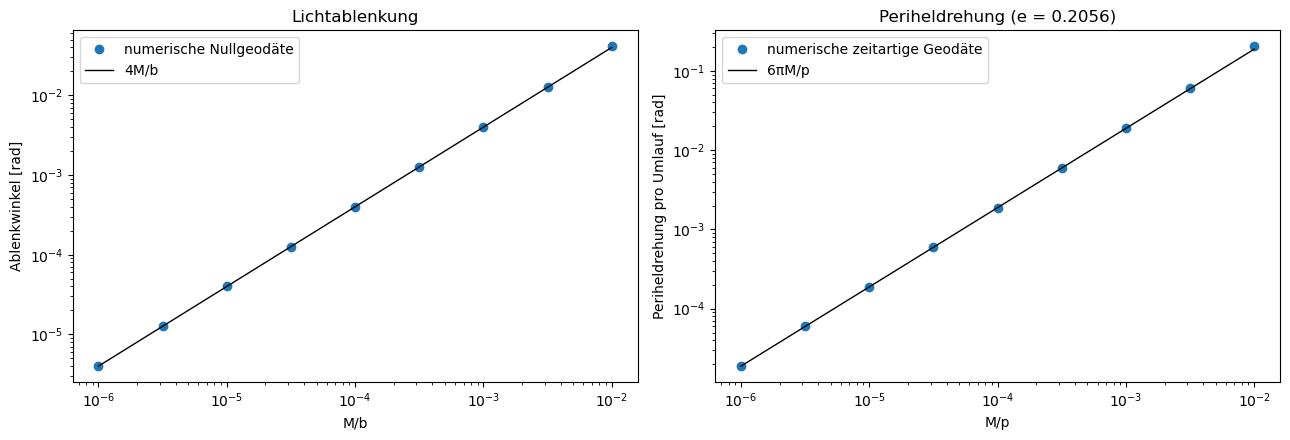

Licht am Sonnenrand: 1.7512″   (4GM/(c²R) = 1.7512″)
Merkur: 5.0185e-07 rad pro Umlauf = 42.98″ pro Jahrhundert   (6πGM/(c²a(1−e²)) = 42.98″)


In [8]:
M_SUN = 1476.6                        # GM/c² of the Sun [m]
R_SUN = 6.957e8                       # radius of the Sun [m]
A_MERC, E_MERC, P_MERC = 5.7909e10, 0.2056, 87.969   # semi-major axis [m], eccentricity, period [days]
RAD_TO_ARCSEC = 180 / np.pi * 3600

def deflection(eps):
    leave = lambda phi, w: w[0]
    leave.terminal, leave.direction = True, -1
    sol = solve_ivp(lambda phi, w: [w[1], -w[0] + 3 * eps * w[0] ** 2], [0, 4], [0.0, 1.0],
                    method="DOP853", rtol=1e-13, atol=1e-16, events=leave)
    return sol.t_events[0][0] - np.pi

def perihelion_shift(eps, e):
    peri = lambda phi, w: w[1]
    peri.direction = -1                       # w' changes from + to −: maximum of w = perihelion
    sol = solve_ivp(lambda phi, w: [w[1], -w[0] + 1 + 3 * eps * w[0] ** 2], [0, 2 * np.pi + 1], [1 + e, 0.0],
                    method="DOP853", rtol=1e-13, atol=1e-16, events=peri)
    return [p for p in sol.t_events[0] if p > 1][0] - 2 * np.pi

eps_grid = np.logspace(-6, -2, 9)
defl = np.array([deflection(e_) for e_ in eps_grid])
prec = np.array([perihelion_shift(e_, E_MERC) for e_ in eps_grid])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(eps_grid, defl, "o", label="numerische Nullgeodäte")
axes[0].loglog(eps_grid, 4 * eps_grid, c="black", lw=1, label="4M/b")
axes[0].set_xlabel("M/b")
axes[0].set_ylabel("Ablenkwinkel [rad]")
axes[0].set_title("Lichtablenkung")
axes[0].legend()
axes[1].loglog(eps_grid, prec, "o", label="numerische zeitartige Geodäte")
axes[1].loglog(eps_grid, 6 * np.pi * eps_grid, c="black", lw=1, label="6πM/p")
axes[1].set_xlabel("M/p")
axes[1].set_ylabel("Periheldrehung pro Umlauf [rad]")
axes[1].set_title(f"Periheldrehung (e = {E_MERC})")
axes[1].legend()
fig.tight_layout()
plt.show()

d_sun = deflection(M_SUN / R_SUN)
eps_merc = M_SUN / (A_MERC * (1 - E_MERC ** 2))
shift = perihelion_shift(eps_merc, E_MERC)
per_century = shift * 36525 / P_MERC
print(f"Licht am Sonnenrand: {d_sun * RAD_TO_ARCSEC:.4f}″   (4GM/(c²R) = {4 * M_SUN / R_SUN * RAD_TO_ARCSEC:.4f}″)")
print(f"Merkur: {shift:.4e} rad pro Umlauf = {per_century * RAD_TO_ARCSEC:.2f}″ pro Jahrhundert   "
      f"(6πGM/(c²a(1−e²)) = {6 * np.pi * eps_merc * 36525 / P_MERC * RAD_TO_ARCSEC:.2f}″)")

* Das **linke Bild** zeigt den Ablenkwinkel der numerischen Nullgeodäten gegen $M/b$, doppelt logarithmisch: Die Punkte liegen über vier Dekaden auf der Linie $4M/b$. Doppelter Abstand gibt halbe Ablenkung.
* Das **rechte Bild** zeigt dasselbe für die Periheldrehung einer Bahn mit der Exzentrizität des Merkur, $e = 0{,}2056$: Die Punkte folgen $6\pi M/p$. Erst nahe $10^{-2}$ trägt die nächste Ordnung in $M/b$ bzw. $M/p$, die beide Formeln vernachlässigen, einige Prozent bei.
* Die **Ausgabe** wendet das auf die Sonne an ($GM/c^2 = 1476{,}6$ m): Ein Strahl am Sonnenrand wird um $1{,}7512$″ abgelenkt, wie die Formel $4GM/(c^2R_\odot)$ vorhersagt. Das Perihel des Merkur dreht sich um $5{,}02\cdot10^{-7}$ rad pro Umlauf, $42{,}98$″ pro Jahrhundert: der Teil der beobachteten Periheldrehung, den der Zug der anderen Planeten nicht erklären kann.

#### **Ergebnis**

Beim Lauf vom 2026-10-31:

- **Sphäre:** $\Gamma^\theta{}_{\phi\phi} = -\sin\theta\cos\theta$ (ausgegeben als $-\sin 2\theta/2$), $\Gamma^\phi{}_{\theta\phi} = \cot\theta$; Ricci-Skalar $R = 2/a^2$, also $K = 1/a^2$. In zwei Dimensionen hat der Riemann-Tensor eine einzige unabhängige Komponente.
- **Geodäten:** Die numerische Geodäte bleibt bis auf $7\cdot10^{-11}$ in einer Ebene durch den Mittelpunkt, ein Großkreis; $g(v,v)$ und $\sin^2\theta\,\dot\phi$ sind bis auf $10^{-10}$ erhalten, die Genauigkeit des Integrators.
- **Holonomie:** Der transportierte Vektor kommt um genau $2\pi(1 - \cos\theta_0)$ gedreht zurück, die über die Kappe integrierte Krümmung (Abweichung unter $10^{-10}$ Grad für alle 40 Schleifen); bei $\theta_0 = 60°$ ist das eine halbe Drehung. Um den Äquator, der selbst eine Geodäte ist, beträgt die Drehung volle 360°, der Vektor kommt also unverändert zurück.
- **Torus:** $K = \cos\theta / \left(r(R + r\cos\theta)\right)$, positiv auf der äußeren Hälfte wie eine Sphäre (bis $+1/3$ für $R = 2$, $r = 1$), negativ auf der inneren wie ein Sattel (bis $-1$). Die Gesamtkrümmung ist null bis auf $10^{-15}$, für die Sphäre $4\pi$: Gauß–Bonnet mit $\chi = 0$ und $\chi = 2$.
- **Schwarzschild:** Ricci-flach (Vakuum), aber gekrümmt: Kretschmann-Skalar $48M^2/r^6$, erste Bianchi-Identität in allen 256 Komponenten erfüllt. Der Gezeitentensor ist $-2M/r^3$ radial und $M/r^3$ seitlich, wie in Abschnitt 7 der Theorie. Gezeitenbeschleunigung zwischen Kopf und Füßen: $6\cdot10^{-6}$ m/s² auf der Erde, $2\cdot10^{8}$ m/s² am Horizont eines Schwarzen Lochs von 10 Sonnenmassen, aber nur $10^{-3}$ m/s² am Horizont von Sgr A*: Weil der Horizont wie $M$ wächst, fällt die Gezeitenkraft dort wie $1/M^2$.
- **FLRW:** $G_{tt} = 3(\dot a/a)^2$, $G_{xx} = -(2a\ddot a + \dot a^2)$, und $\nabla_\mu G^{\mu\nu} = 0$ für eine beliebige Funktion $a(t)$: Die kontrahierte Bianchi-Identität gilt identisch.
- **Sonne:** Die Nullgeodäte wird um 1,7512″ abgelenkt (Formel $4GM/(c^2R_\odot)$: 1,7512″). Das Perihel des Merkur dreht sich um $5{,}02\cdot10^{-7}$ rad pro Umlauf, 42,98″ pro Jahrhundert (beobachteter anomaler Anteil: etwa 43″). Die doppelt logarithmischen Bilder zeigen die lineare Skalierung $4M/b$ und $6\pi M/p$ über vier Dekaden; die kleine Abweichung bei großem $M/b$ ist die nächste Ordnung in $M/b$.

#### **Variationen**

Erst die Vorhersage aufschreiben, dann den Code ändern:

1. **Hyperbolische Ebene:** Nimm die Metrik $ds^2 = (dx^2 + dy^2)/y^2$ (obere Halbebene). *(Vorhersage: überall $K = -1$; Geodäten sind senkrechte Geraden und Halbkreise mit Mittelpunkt auf der $x$-Achse.)*
2. **Polarkoordinaten in der flachen Ebene:** $ds^2 = dr^2 + r^2 d\phi^2$ hat Christoffel-Symbole ungleich null. Hat sie Krümmung? Was sagt das über den Unterschied zwischen $\Gamma$ und $R$?
3. **Geodäten auf dem Torus:** Integriere Geodäten auf dem Torus, die auf dem äußeren Äquator unter verschiedenen Winkeln starten. Welche bleiben außen, und warum passt das zum Vorzeichen von $K$?
4. **Perihel anderer Körper:** Berechne die Drehung pro Jahrhundert für die Venus ($a = 1{,}0821\cdot10^{11}$ m, $e = 0{,}0068$, $P = 224{,}7$ d) und die Erde. *(Vorhersage: etwa 8,6″ und 3,8″.)*
5. **Photonensphäre:** Für Licht hat $w'' + w = 3\varepsilon w^2$ eine Kreisbahn. Bei welchem $r$ in Einheiten von $M$? *(Vorhersage: $r = 3M$.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum ist die partielle Ableitung eines Vektors kein Tensor, und was repariert die kovariante Ableitung?</summary>

Bei einem Koordinatenwechsel bekommt $\partial_\mu V^\nu$ einen Zusatzterm mit den zweiten Ableitungen des Koordinatenwechsels, weil sich die Basisvektoren von Punkt zu Punkt ändern. Der Christoffel-Term in $\nabla_\mu V^\nu = \partial_\mu V^\nu + \Gamma^\nu{}_{\mu\lambda}V^\lambda$ transformiert sich mit genau dem entgegengesetzten Zusatzterm, also ist die Summe ein Tensor.
</details>

<details><summary>2. Welche zwei Bedingungen legen den Levi-Civita-Zusammenhang fest?</summary>

Er ist torsionsfrei ($\Gamma^\lambda{}_{\mu\nu}$ symmetrisch in den unteren Indizes) und mit der Metrik verträglich ($\nabla g = 0$, Längen und Winkel überstehen den Paralleltransport). Zusammen bestimmen sie $\Gamma$ eindeutig aus den ersten Ableitungen der Metrik.
</details>

<details><summary>3. Was ist eine Geodäte, und wie findet man die Christoffel-Symbole von Hand am schnellsten?</summary>

Eine Kurve, die ihren eigenen Tangentialvektor parallel transportiert, die geradeste mögliche Kurve und eine stationäre Kurve der Länge. Man schreibt die Euler–Lagrange-Gleichungen von $\tfrac12g_{\mu\nu}\dot x^\mu\dot x^\nu$ auf und liest die Koeffizienten von $\dot x^\mu\dot x^\nu$ ab.
</details>

<details><summary>4. Wann ist eine Größe entlang jeder Geodäte erhalten?</summary>

Wenn die Metrik nicht von einer Koordinate $x^k$ abhängt: Dann ist $p_k = g_{k\nu}\dot x^\nu$ erhalten, und $\partial_k$ ist ein Killing-Vektor. Beispiele sind $\sin^2\theta\,\dot\phi$ auf der Sphäre sowie Energie und Drehimpuls bei Schwarzschild.
</details>

<details><summary>5. Wie ist der Riemann-Tensor definiert, und wie viele unabhängige Komponenten hat er?</summary>

Über den Kommutator kovarianter Ableitungen, $[\nabla_\mu, \nabla_\nu]V^\rho = R^\rho{}_{\sigma\mu\nu}V^\sigma$. Wegen seiner Symmetrien hat er $n^2(n^2-1)/12$ unabhängige Komponenten: 1 auf einer Fläche (die Gauß-Krümmung), 20 in der Raumzeit.
</details>

<details><summary>6. Was ist Holonomie, und um wie viel dreht sich ein Vektor um einen Breitenkreis?</summary>

Die Drehung eines Vektors, den man um eine geschlossene Schleife parallel transportiert; auf einer Fläche gleich $\int K\,dA$ über das eingeschlossene Gebiet. Um den Kreis $\theta = \theta_0$ auf der Einheitssphäre ist das die Fläche der Kappe, $2\pi(1 - \cos\theta_0)$.
</details>

<details><summary>7. Was sagt Gauß–Bonnet, und warum ist die Gesamtkrümmung eines Torus null?</summary>

$\int K\,dA = 2\pi\chi$ über eine geschlossene Fläche, mit der Euler-Charakteristik $\chi$. Der Torus hat $\chi = 0$: Die positive Krümmung außen und die negative um das Loch heben sich genau auf, egal welche Radien.
</details>

<details><summary>8. Wie kann eine Raumzeit Ricci-flach und trotzdem gekrümmt sein?</summary>

Der Ricci-Tensor ist nur eine Kontraktion des Riemann-Tensors. In vier Dimensionen hat Riemann 20 Komponenten und Ricci 10; die anderen 10 (der Weyl-Tensor) können im Vakuum ungleich null sein. Sie beschreiben Gezeitenkräfte und Gravitationswellen.
</details>

<details><summary>9. Warum kann der Einstein-Tensor links in den Feldgleichungen stehen?</summary>

Die kontrahierte Bianchi-Identität sorgt dafür, dass $\nabla_\mu G^{\mu\nu} = 0$ für jede Metrik gilt. Der Energie-Impuls-Tensor rechts muss erhalten sein, und genau das garantiert die Geometrie; in der Kosmologie ergibt das die Kontinuitätsgleichung.
</details>

<details><summary>10. Was sind Gezeitenkräfte in der Sprache der Geometrie, und warum sind sie am Horizont eines supermassereichen Schwarzen Lochs schwach?</summary>

Die Relativbeschleunigung benachbarter Geodäten, gegeben durch den Riemann-Tensor (geodätische Abweichung). Am Horizont $r = 2M$ ist die Gezeitenkraft $\sim M/r^3\propto1/M^2$, sie fällt also mit der Masse des Schwarzen Lochs.
</details>

<details><summary>11. Welcher Term in der Bahngleichung ist neu in der Allgemeinen Relativitätstheorie, und was sagt er voraus?</summary>

Der Term $3Mu^2$ in $u'' + u = \kappa M/L^2 + 3Mu^2$. Er lenkt Licht um $4M/b$ ab (1,75″ am Sonnenrand) und dreht ein Perihel um $6\pi M/p$ pro Umlauf (43″ pro Jahrhundert beim Merkur).
</details>

#### **Nächste Schritte**

- **Differentialformen und Cartans Strukturgleichungen:** Krümmung mit Tetraden und Zusammenhangs-1-Formen statt Christoffel-Symbolen berechnen; für Metriken mit vielen Symmetrien geht das viel schneller.
- **Feldgleichungen als Randwertproblem:** die Schwarzschild-Metrik herleiten, indem man $R_{\mu\nu} = 0$ für einen statischen, kugelsymmetrischen Ansatz mit sympy löst.
- **Gravitationswellen:** $g_{\mu\nu} = \eta_{\mu\nu} + h_{\mu\nu}$ linearisieren, zeigen, dass der Riemann-Tensor einer ebenen Welle eichinvariant ist, und ihn mit dem von LIGO gemessenen Strain verbinden (geodätische Abweichung zwischen den Spiegeln).
- **Faserbündel:** Paralleltransport und Holonomie verallgemeinern sich auf Eichfelder; die Berry-Phase eines Spins in einem rotierenden Feld ist dieselbe Holonomie auf der Bloch-Kugel wie in Experiment 3, mit dem Raumwinkel an Stelle der Kappenfläche (Notebooks [Vektoranalysis](https://github.com/deltorobarba/science/blob/main/maths/vectorcalculus.ipynb) und [Projektive Geometrie](https://github.com/deltorobarba/science/blob/main/maths/projectivegeometry.ipynb)).

#### **Referenzen**

- Carroll, S. M. (2004): *Spacetime and Geometry*, Addison-Wesley, Kap. 2 (Mannigfaltigkeiten), Kap. 3 (Krümmung, Bianchi-Identitäten, geodätische Abweichung), Kap. 5 (Schwarzschild-Bahnen, Lichtablenkung, Perihel). Skriptfassung: arXiv:gr-qc/9712019.
- Misner, C. W., Thorne, K. S. & Wheeler, J. A. (1973): *Gravitation*, Freeman.
- do Carmo, M. P. (1976): *Differential Geometry of Curves and Surfaces*, Prentice-Hall (Gauß-Krümmung, Gauß–Bonnet).
- Schutz, B. (2009): *A First Course in General Relativity*, 2. Aufl., Cambridge University Press.
- Will, C. M. (2014): *The Confrontation between General Relativity and Experiment*, Living Rev. Relativ. 17, 4 (Tests mit Lichtablenkung und Perihel).